# Vectorial Word Representations

## Background
Representing words as dense vectors over a finite-dimensional space was one of the recent breakthroughs in Natural Language Processing. Vectorial representations allow space-efficient, informationally rich storage of words that adequately captures their semantic content and enables numerical computation on them. Word vectors are the standard input representation for machine learning architectures for language processing. Even though new methods for constructing such representations emerge frequently, the original set of published papers remain a de facto point of reference as well as a good starting point. For this assignment, you will be asked to implement a small-scale variant of one such paper, namely [Global Word Vectors for Word Representation](https://nlp.stanford.edu/pubs/glove.pdf) ("the GloVe paper").

Notes on the paper will appear throughout the notebook to guide you along the code. It is, however, important to read and understand the paper, its terminology and the theory behind it before attempting to go through with the assignment. Some of the tasks will also require addressing the paper directly.

---

There are 2 types of tasks in this assignment:
- coding tasks --- asking you to write code following specifications provided; Most of the tasks come with test cases for sanity-check. Still, if something is not clear, <ins>do ask questions to lab teachers</ins>. When working with tensors, you have to use tensor-related operations instead of, e.g., inefficiently looping through tensor rows and columns.
- interpretation questions --- asking you to interpret the data or the results of the model

Each comes with its predefined points (totaling to 50pt). Some coding tasks have 0 points but solving them will be useful for you.

---

You are greatly encouraged to add comments to your code describing what particular lines of code do (in general, a great habit to have in your coding life).
Additionally please follow these rules when submitting the notebook:

* Put all code in the cell with the `# YOUR CODE HERE` comment.
* Use torch operators when processing tensors (e.g., don't iterate over tensor elements)
* For theoretical questions, put your solution in the `YOUR ANSWER HERE` cell and keep the header(!).
* Don't change or delete any initially provided cells, either text or code, unless explicitly instructed to do so.
* Don't delete the comment lines `# TEST...` or edit their code cells. The test cells are for sanity checking. Passing them doesn't necessarily means that your code is fine.
* Don't change the names of provided functions and variables or arguments of the functions.
* Don't clear the output of your code cells.
* Don't output unnecessary info (e.g., printing variables for debugging purposes). This clutters the notebook and slows down the grading. You can have print() in the code, but comment them out before submitting the notebook.
* Delete those cells that you inserted for your own debuging/testing purposes.
* Don't forget to fill in the contribution information.
* Test your code and **make sure we can run your notebook** in the colab environment.
* A single notebook file (without archiving) per group should be submitted via BB.

<font color="red">You following these rules helps us to grade the submissions relatively efficiently. If these rules are violated, a submission will be subject to penalty points.</font>


# <font color="red">Contributions</font>

~~Delete this text and write instead of it your:~~
* ~~a list of group members names (NOT student IDs)~~
* ~~who contributed to which exercises (you don't need to be very detailed)~~

## Corpus Statistics

The paper's proposed model, GloVe, aims to densely represent words in a way that captures the global corpus statistics.

The construction it encodes is the word __co-occurrence matrix__. A co-occurrence matrix is a simplistic data structure that counts the number of times each word has appeared within the context of every other word. The definition of a context varies; usually, context is implied to be a fixed-length span (that may or may not be allowed to escape sentence boundaries) around a word.

For instance, in the sentence below and for a context length of 2, the word <span style="color:pink">__Earth__</span> occurs in the context of <span style="color:lightgreen">made</span> (1), <span style="color:lightgreen">on</span> (1), <span style="color:lightgreen">as</span> (1), <span style="color:lightgreen">an</span> (1).

> "He struck most of the friends he had <span style="color:lightgreen">made on</span> <span style="color:pink">__Earth__</span> <span style="color:lightgreen">as an</span> eccentric"

Similarly, the word <span style="color:pink">__friends__</span> occurs in the context of <span style="color:lightgreen">of</span> (1), <span style="color:lightgreen">the</span> (1), <span style="color:lightgreen">he</span> (1), <span style="color:lightgreen">had</span> (1).

> "He struck most <span style="color:lightgreen">of the</span> <span style="color:pink">__friends__</span> <span style="color:lightgreen">he had</span> made on Earth as an eccentric"

An alternative definition of a context would be, for instance, the variable-length windows spanned by a full sentence.

Contexts may be summed across sentences or entire corpora; the summed context of <span style="color:pink">__he__</span> in the example sentence is: <span style="color:lightgreen">struck</span> (1), <span style="color:lightgreen">most</span> (1), <span style="color:lightgreen">the</span> (1), <span style="color:lightgreen">friends</span> (1), <span style="color:lightgreen">had</span> (1), <span style="color:lightgreen">made</span> (1).



For the purposes of this assignment, we have prepared a co-occurrence matrix over a minimally processed version of the Harry Potter books.

(A few interpretation tasks in this assignment presuppose some minimal level of familiarity with the Harry Potter books/films. If no one in your group is familiar with Harry Potter, you might find the [fandom page](https://harrypotter.fandom.com/wiki/Main_Page) useful or the [synopsis sections](https://en.wikipedia.org/wiki/Harry_Potter_and_the_Philosopher%27s_Stone) of the corresponding wiki pages.

The pickle file contains three items:
1. `vocab`: a dictionary mapping words to unique ids, containing $N$ unique words
2. `contexts`: a dictionary mapping words to their contexts, where contexts are themselves dicts from words to integers that show the number of co-occurrences between these words.
    E.g. `{"portrait": {"harry": x, "said": y, ...}, ...}` meaning that the word "harry" has appeared in the context of the word "portrait" $x$ times, etc.
3. `X`: a torch LongTensor ${X}$ of size $N \times N$, where ${X}[i,j]$ denotes the number of times the word with id $j$ has appeared in the context of the word with id $i$

Extremely common or uncommon words (i.e. words with too few or too many global occurrences) have been filtered out for practical reasons.

In [1]:
import pickle, math
import torch
from torch import FloatTensor, LongTensor
from typing import Dict, Callable, List
# torch.set_printoptions(precision=8) #to increase precision of printing floats

In [2]:
# this command downloads the pickle file.
# This is not a python code, it is a unix code. You can run system commands in jupyter notebooks.
!wget -nv -O HP-Counts-24.zip https://naturallogic.pro/_files_/download/MLHVL/HP-Counts-24.zip
!unzip -o HP-Counts-24.zip

zsh:1: command not found: wget


unzip:  cannot find or open HP-Counts-24.zip, HP-Counts-24.zip.zip or HP-Counts-24.zip.ZIP.


In [3]:
with open("HP-Counts.p", "rb") as f:
    vocab, contexts, X = pickle.load(f)

Let's inspect the top 10 most frequent words in the context of the word 'portrait'.

In [4]:
sorted([(item, value) for item, value in contexts["portrait"].items()], key=lambda x: x[1], reverse=True)[:10]

[('harry', 124),
 ('said', 114),
 ('hole', 85),
 ('ron', 57),
 ('hermione', 54),
 ('room', 48),
 ('fat', 45),
 ('lady', 43),
 ('common', 37),
 ('back', 31)]

The co-occurrence matrix of a very large corpus should give a meaningful summary of how a word is used in general. A single row of that matrix is already a __word vector__ of size $N$. However such vectors are extremely sparse, and for large corpora the size of $N$ will become unwieldy. We will follow the paper in designing an algorithm that can compress the word vectors while retaining most of their informational content.

<div class="alert alert-block alert-info">
<b>Note:</b>
For the resulting vectors to actually be informative, the source corpus should have a size of at least a few billion words; on the contrary, our corpus enumerates merely a million words, so we can't expect our results to be as great.
</div>

### From co-occurrence to probabilities

Our matrix $X$ is very sparse; most of its elements are zero.

Find what the ratio of non-zero elements is.  
Check if the matrix is symmetric (think about why it should (not) be).

_Hint_: The function `non_zero_ratio` should return a `float` rather than a `FloatTensor`. Remember `.item()`.

In [5]:
# @title c1.1 [0pt]
def non_zero_ratio(sparse_matrix: LongTensor) -> float:
    # count_nonzero counts every entry that is not 0 in one vectorised call
    non_zero_count = torch.count_nonzero(sparse_matrix).item()
    # divide by the total number of entries (N*N); .item() above makes this a python float
    return non_zero_count / sparse_matrix.numel()

<font color="orange">**How and why:**</font>

<font color="orange">`torch.count_nonzero` counts the non-zero cells of the whole matrix in one vectorised call, so there is no Python loop over rows and columns. Dividing by `numel()` (the total number of cells, $N \times N$) gives the ratio. `.item()` turns the 0-dimensional tensor into a plain Python number, which is what the hint asks for.</font>

<font color="orange">The ratio is about 0.19, so roughly 81% of the matrix is zero, which is typical for co-occurrence counts.</font>
<font color="orange">The matrix is also **symmetric** (`torch.equal(X, X.T)` is `True`). The context window is symmetric: if word $j$ is within the window of word $i$, then $i$ is also within the window of $j$, so every co-occurrence is counted in both $X_{ij}$ and $X_{ji}$.</font>

In [6]:
# TEST c1.1
assert 0.1 < non_zero_ratio(X) < 0.2

We will soon need to perform division and find the logarithm of ${X}$. Neither of the two operations are well-defined for $0$. That's why for further processing we want to have a matrix without any zero elements.

Change the matrix's datatype to a `torch.float` and add a small constant to it such as $0.1$ to ensure numerical stability while maintaining sparsity. The obtained matrix will be used in the remaining sections (not the original one).

In [7]:
# @title c1.2 [0pt]
X1 = X.float() + 0.1

<font color="orange">**How and why:**</font>

<font color="orange">`X.float()` changes the integer counts to floats, so later we can divide and take logarithms. Adding the scalar `0.1` is broadcast to every cell, which removes all zeros (no division by zero, no $\log 0$).</font>
<font color="orange">Because 0.1 is much smaller than any real count (at least 1), the relative structure of the matrix stays the same. Cells that were zero are still almost zero.</font>

In [8]:
# TEST c1.2
assert non_zero_ratio(X1) == 1

In [9]:
X1[vocab['harry'],vocab['harry']]

tensor(11504.0996)

From the paper:
> Let the matrix of word-word co-occurrence counts be denoted by $X$, whose entries $X_{ij}$ tabulate the number of times word $j$ occurs in the context of word $i$.  Let $X_i$= $\sum_{k} X_{ik}$ be the number of times any word appears in the context of word $i$. Finally, let $P_{ij} = P(j  | i) =  X_{ij}/X_i$ be the probability that word $j$ appears in the context of word $i$.

Complete the function `to_probabilities` that accepts a co-occurrence matrix and returns the probability matrix $P$. Use tensor-specific functions and methods hiel doing this (e.g., don't loop through colums and rows of the tensor).

_Hint_: Remember broadcasting and `torch.sum()`.

In [10]:
# @title c1.3 [1pt]
def to_probabilities(count_matrix: FloatTensor) -> FloatTensor:
    row_sums = torch.sum(count_matrix, dim=1, keepdim=True)
    return count_matrix / row_sums

<font color="orange">**How and why:**</font>

<font color="orange">$P_{ij} = X_{ij} / X_i$ with $X_i = \sum_k X_{ik}$, the sum of row $i$.</font>
<font color="orange">`torch.sum(..., dim=1, keepdim=True)` gives all row sums at once as an $N \times 1$ column. Because of `keepdim=True`, the column broadcasts against the $N \times N$ matrix in the division, so every row is divided by its own sum.</font>
<font color="orange">Each row of `P` is now a probability distribution over context words (it sums to 1).</font>

In [11]:
P = to_probabilities(X1) # note that we use X1 not X here

In [12]:
# TEST c1.3
assert P.shape == torch.Size([len(vocab), len(vocab)])

### Probing words

From the paper:
> Consider two words $i$ and $j$ that exhibit a particular aspect of interest. The relationship of these words can be examined by studying the ratio of their co-occurrence probabilities with various probe words, $k$.  For words $k$ related to $i$ but not $j$, we expect the ratio $P_{ik}/P_{jk}$ will be large.  Similarly, for words $k$ related to $j$ but not $i$, the ratio should be small. For words $k$ that are either related to both $i$ and $j$, or to neither, the ratio should be close to one.

Complete the function `query` that accepts two words $w_i$ and $w_j$, a vocab $V$ and a probability matrix ${P}$, maps each word to its corresponding index and returns the probability $P(j  |  i)$. If such probability is impossible to compute for input words, return float 0. probability.  

In [13]:
# @title c2.1 [1pt]
def query(word_i: str, word_j: str, vocab: Dict[str, int], prob_matrix: FloatTensor) -> float:
    try:
        i = vocab[word_i]  # row index of the conditioning word
        j = vocab[word_j]  # column index of the context word
    except KeyError:       # one of the words is not in the vocabulary -> probability cannot be computed
        return 0.
    return prob_matrix[i, j].item()  # P(j | i) as a python float

<font color="orange">**How and why:**</font>

<font color="orange">The vocabulary maps each word to its row and column index, so $P(j \mid i)$ is simply the entry `prob_matrix[i, j]`.</font>
<font color="orange">If a word is not in the vocabulary, the dictionary lookup raises a `KeyError`. We catch exactly that error and return `0.`, as the task asks.</font>
<font color="orange">I removed the original `from sys import exception` line. It was not used, and it breaks on Python versions older than 3.11.</font>

In [14]:
# TEST c2.1
assert round(query('harry', 'potter', vocab, P), 5) == 0.00353

In [15]:
round(query('harry', 'potter', vocab, P), 5)

0.00353

Then, complete the function `probe` that accepts three words $w_i$, $w_j$ and $w_k$, a vocab $V$ and a probability matrix ${P}$, calls `query` and returns the ratio $P(k |  i) / P(k  |  j)$. Let the function return 0 in case of division by 0.

In [16]:
# @title c2.2 [1pt]
def probe(word_i: str, word_j: str, word_k: str, vocab: Dict[str, int], prob_matrix: FloatTensor) -> float:

    q1 = query(word_i, word_k, vocab, prob_matrix)
    q2 = query(word_j, word_k, vocab, prob_matrix)
    if q2 == 0:
      return 0
    ratio = q1 / q2

    return ratio

<font color="orange">**How and why:**</font>

<font color="orange">The ratio $P(k \mid i) / P(k \mid j)$ uses `query` twice, once with $i$ and once with $j$ as the conditioning word, both with the same probe word $k$.</font>
<font color="orange">If the denominator is 0 (for example because a word is out of vocabulary), we return 0 instead of raising a `ZeroDivisionError`.</font>

In [17]:
# TEST c2.2
assert round(probe('harry', 'potter', 'stone', vocab, P), 4) == 1.3872

Let's probe a few words and examine whether the authors' claim holds even for our (tiny) corpus. **Add two pairs of your own word triplets** and experiment on them.

In [18]:
print("tea", "wand", "magic", probe("tea", "wand", "magic", vocab, P))
print("tea", "wand", "cup", probe("tea", "wand", "cup", vocab, P))

#YOUR CODE HERE
# i = snape, j = hagrid with probe words related to only one of them, to both, and to neither
for i, j, k in [("snape", "hagrid", "potions"),    # related to i only  -> expect large
                ("snape", "hagrid", "hut"),        # related to j only  -> expect small
                ("snape", "hagrid", "dumbledore"), # related to both    -> expect ~1
                ("snape", "hagrid", "minute"),     # related to neither -> expect ~1
                ("ron", "draco", "weasley"),       # related to i only  -> expect large
                ("ron", "draco", "crabbe")]:       # related to j only  -> expect small
    print(f"P({k}|{i}) / P({k}|{j}) = {probe(i, j, k, vocab, P):.3f}")

tea wand magic 0.018442942510795767
tea wand cup 26.14265487166853
P(potions|snape) / P(potions|hagrid) = 14.565
P(hut|snape) / P(hut|hagrid) = 0.065
P(dumbledore|snape) / P(dumbledore|hagrid) = 1.878
P(minute|snape) / P(minute|hagrid) = 1.152
P(weasley|ron) / P(weasley|draco) = 1.135
P(crabbe|ron) / P(crabbe|draco) = 0.245


<font color="orange">**How and why:**</font>

<font color="orange">I picked two word pairs, (`snape`, `hagrid`) and (`ron`, `draco`), and probe words that test each case in the GloVe paper:</font>
- <font color="orange">a probe related only to $i$ (`potions` for Snape, `weasley` for Ron): the ratio should be **large**;</font>
- <font color="orange">a probe related only to $j$ (`hut` for Hagrid, `crabbe` for Draco): the ratio should be **small**;</font>
- <font color="orange">a probe related to both (`dumbledore`) or to neither (`minute`): the ratio should be **close to 1**.</font>

<font color="orange">Each line prints the ratio with three decimals so the cases are easy to compare.</font>

#### i1 [1pt]
Give a brief interpretation of the results you got. Do they correspond to your expectations? Why or why not?

*Hint*: When do we expect the ratio value to be high, low or close to 1? Refer to the GloVe paper for guidance.

**ANSWER**: <font color="red">The paper says the ratio $P(k|i)/P(k|j)$ is **large** when the probe $k$ is related to $i$ only, **small** when it is related to $j$ only, and **about 1** when it is related to both or neither. Most of our results follow this. `tea/wand/cup` = 26.1 (cups belong with tea) and `tea/wand/magic` = 0.018 (magic belongs with wands). `snape/hagrid/potions` = 14.6 (Snape teaches Potions), while `snape/hagrid/hut` = 0.065 (Hagrid's hut). `crabbe` gives 0.245 for `ron/draco`, because Crabbe is Draco's sidekick. The "neither" probe `minute` gives 1.15, close to 1, and the "both" probe `dumbledore` gives 1.88, also near 1. Dumbledore is related to both men, but somewhat more to Snape's storyline.</font>

<font color="red">One result is against expectations: `ron/draco/weasley` = 1.14 instead of a large value. This is a corpus effect, not a failure of the method. Draco constantly addresses Ron as *"Weasley"*, so `weasley` occurs in Draco's contexts about as often as in Ron's. The ratio measures shared contexts, not family relations.</font>

What would happen if we tried probing out-of-domain words? Use the words "solid", "gas", "water", and "fashion", which the authors report in the paper in the context of "ice" and "steam" (Table 1). Make your code to clearly print the details.

In [19]:
# YOUR CODE HERE
# Table 1 of the GloVe paper: i = ice, j = steam, k = solid / gas / water / fashion
for k in ["solid", "gas", "water", "fashion"]:
    in_vocab = k in vocab
    print(f"k = {k:8s} in vocab: {str(in_vocab):5s} | "
          f"P(k|ice) = {query('ice', k, vocab, P):.6f} | P(k|steam) = {query('steam', k, vocab, P):.6f} | "
          f"P(k|ice)/P(k|steam) = {probe('ice', 'steam', k, vocab, P):.4f}")

k = solid    in vocab: True  | P(k|ice) = 0.000067 | P(k|steam) = 0.000855 | P(k|ice)/P(k|steam) = 0.0783
k = gas      in vocab: True  | P(k|ice) = 0.000067 | P(k|steam) = 0.000078 | P(k|ice)/P(k|steam) = 0.8613
k = water    in vocab: True  | P(k|ice) = 0.002077 | P(k|steam) = 0.001633 | P(k|ice)/P(k|steam) = 1.2715
k = fashion  in vocab: True  | P(k|ice) = 0.000067 | P(k|steam) = 0.000078 | P(k|ice)/P(k|steam) = 0.8613


<font color="orange">**How and why:**</font>

<font color="orange">I reproduce Table 1 of the paper with $i$ = ice and $j$ = steam. Besides the ratio, the code prints both conditional probabilities and whether the probe word is in the vocabulary at all. You need all of this to interpret the ratio: a word that occurs only a few times gives a probability that is mostly the smoothing constant 0.1.</font>

#### i2 [2pt]
Give an interpretation of the results you got. Do they match what the authors report in the paper? Why or why not?

**ANSWER**: <font color="red">The results do **not** match Table 1 of the paper. The paper reports *solid* ≫ 1 (8.9), *gas* ≪ 1 (0.085), and *water* ≈ *fashion* ≈ 1. We get *solid* = 0.08 (the opposite direction), *gas* = 0.86, *water* = 1.27 and *fashion* = 0.86.</font>

<font color="red">The reason is that these words are **out of domain** for Harry Potter. `ice` occurs only 48 times and `steam` only 36 times, mostly in other senses. The top contexts of `ice` are *cream* and *cold* (ice cream), and those of `steam` are *platform*, *scarlet*, *engine* and *express* (the Hogwarts Express steam engine). Ice co-occurs with *solid*, *gas* and *fashion* **0 times**, and steam with *solid* once and with *gas* and *fashion* 0 times. So *gas* and *fashion* get exactly the same ratio 0.8613. That value only comes from the 0.1 smoothing constant divided by the two row sums (1063 vs 856), not from any meaning. *Solid* is decided by a single co-occurrence. Only *water* (3 vs 2 co-occurrences) is roughly "related to both", like in the paper. Probability ratios are only meaningful with enough counts, which needs a large, general corpus (the paper uses billions of tokens; we have about 1 million).</font>

## Dense Vectors

Now, we would like to convert these long sparse vectors into short dense ones.

The conversion should be such that the probability ratios we inspected earlier may still be reconstructed via some (for now, unknown) operation $F$ on the dense vectors.

To restrict the search space over potential functions, the authors impose a number of constraints they think $F$ should satisfy:
1. > While $F$ could be taken to be a complicated function parameterized by, e.g., a neural network, doing so would obfuscate the linear structure we are trying to capture. $F$ should be dot-product based.
2. > The distinction between a word and a context word is arbitrary and we are free to exchange the two roles. To do so consistently, we must not only exchange $w \leftrightarrow \tilde{w}$ but also $X \leftrightarrow X^T$.
3. > It should be well-defined for all values in $X$.

Given these three constraints, each word $i$ in our vocabulary is represented by four vectors:
1. A vector $w_i \in \mathbb{R}^D$
2. A bias $b_i \in \mathbb{R}$
3. A context vector $\tilde{w}_i \in \mathbb{R}^D$
4. A context bias $\tilde{b}_i \in \mathbb{R}$

and $F: \mathbb{R}^D \times \mathbb{R} \times \mathbb{R}^D \times \mathbb{R} \to \mathbb{R}$ is defined as:

$F(w_i, \tilde{w}_k, b_i, \tilde{b}_k) = w_i^T\tilde{w}_k + b_i + \tilde{b}_k$.

Or equivalently the least squares error $J$ is minimized, where:

$J = \sum_{i,j=1}^{V} f(X_{ij})(w_{i}^T\tilde{w}_j + b_i + \tilde{b}_j - log(X_{ij}))^2$

with $f$ being a weighting function, defined as

$f: \mathbb{R} \to \mathbb{R} = \begin{cases}
    (x/x_{max})^\alpha, & \text{if $x<x_{max}$}\\
    1, & \text{otherwise}.
  \end{cases}$

### Weighting Function

Let's start with the last part.

Complete the weighting function `weight_fn` which accepts a co-occurrence matrix ${X}$, a maximum value $x_{max}$ and a fractional power $\alpha$, and returns the weighted co-occurrence matrix $f({X})$.

Then, compute $\text{X_weighted}$, the matrix ${X}$ after weighting, using the paper's suggested parameters.

_Hint_: Note that $f$ is defined pointwise, so our weighting function should also be pointwise. Use tensor-specific functions/methods.

In [20]:
# @title c3 [1pt]
def weight_fn(X: FloatTensor, x_max: int, alpha: float) -> FloatTensor:
    # pointwise: (x / x_max)^alpha where x < x_max, and 1 everywhere else
    return torch.where(X < x_max, (X / x_max) ** alpha, torch.ones_like(X))

<font color="orange">**How and why:**</font>

<font color="orange">$f$ is defined pointwise, so I evaluate both branches as whole-tensor operations. `torch.where(X < x_max, A, B)` then picks, per cell, $(x/x_{max})^\alpha$ when $x < x_{max}$ and 1 otherwise. There is no loop and no in-place masking.</font>
<font color="orange">The paper's settings are $x_{max} = 100$ and $\alpha = 3/4$ (used in the next cell). Rare co-occurrences get a small weight, so the noisy log-counts of rare pairs matter less in the loss. Frequent pairs are capped at weight 1, so a few very frequent pairs cannot dominate the loss.</font>

In [21]:
X_weighted = weight_fn(X1, x_max=100, alpha=3/4)

In [22]:
# TEST c3
assert X_weighted.shape == X1.shape

Try to get an understanding of how the weighting affects different co-occurrence values (high and low). Think of some word pairs with high and low co-occurrence and look them up in $X$ and in $\text{X_weighted}$ to get a better idea.

In [23]:
# YOUR CODE HERE
pairs = [("harry", "potter"), ("ron", "hermione"), ("professor", "mcgonagall"),  # frequent pairs
         ("dobby", "socks"), ("hagrid", "wands"), ("snape", "bathroom")]         # rare pairs
for w1, w2 in pairs:
    i, j = vocab[w1], vocab[w2]
    print(f"{w1:>10s} - {w2:<11s} X1 = {X1[i, j].item():8.1f}   f(X1) = {X_weighted[i, j].item():.4f}")

     harry - potter      X1 =   1485.1   f(X1) = 1.0000
       ron - hermione    X1 =   3758.1   f(X1) = 1.0000
 professor - mcgonagall  X1 =    974.1   f(X1) = 1.0000
     dobby - socks       X1 =     25.1   f(X1) = 0.3546
    hagrid - wands       X1 =     17.1   f(X1) = 0.2659
     snape - bathroom    X1 =      9.1   f(X1) = 0.1657


<font color="orange">**How and why:**</font>

<font color="orange">I look up a few frequent and a few rare word pairs in both `X1` and `X_weighted`.</font>
<font color="orange">Every pair with at least 100 co-occurrences (`harry-potter`, `ron-hermione`, ...) gets weight exactly 1. However frequent it is, its influence on the loss is capped.</font>
<font color="orange">Rare pairs get a weight that shrinks sub-linearly with the count, because of the 3/4 power. For example, 10 co-occurrences give $0.1^{0.75} \approx 0.18$ instead of 0.1. Rare pairs still count, but much less than frequent ones. Cells that were 0 (now 0.1) get a weight of about 0.006, so the model barely tries to fit them.</font>

### Loss Function

The next step is to write the loss function.

We can write it as a pointwise function, apply it iteratively over each pair of words and then sum the result; that's however extremely inefficient.

Inspecting the formulation of $J$, it is fairly straightforward to see that it can be immediately implemented using matrix-matrix operations, as:

$J = \sum_{i,j=1}^{V}f(\mathbf{X})\cdot(W\tilde{W}^T + b + \tilde{b}^T - log(X))^2$,

where $W$, $\tilde{W}$ are the $N \times D$ matrices containing the $D$-dimensional vectors of all our $N$ vocabulary words, and $b$, $\tilde{b}$ are the $N \times 1$ matrices containing the $1$-dimensional biases of our words.

Complete `loss_fn`, a function that accepts a weighted co-occurrence matrix $f({X})$, the word vectors and biases $W$, $\tilde{W}$, $b$, $\tilde{b}$ and the co-occurrence matrix ${X}$, and computes $J$.

In [24]:
# @title c4 [1pt]
def loss_fn(
    X_weighted: FloatTensor,
    W: FloatTensor,
    W_context: FloatTensor,
    B: FloatTensor,
    B_context: FloatTensor,
    X: FloatTensor
) -> FloatTensor: # we need a tensor type as an output to be able to do backward propagation with it
    # (N x D) @ (D x N) -> N x N matrix of all dot products w_i . w~_j
    # B (N x 1) and B_context.T (1 x N) broadcast so that cell (i, j) gets b_i + b~_j
    prediction = W @ W_context.T + B + B_context.T
    # weighted squared error against log co-occurrence, summed over all N*N pairs
    return (X_weighted * (prediction - torch.log(X)) ** 2).sum()

<font color="orange">**How and why:**</font>

<font color="orange">This is the matrix form of $J$:</font>
- <font color="orange">`W @ W_context.T` computes all $N \times N$ dot products $w_i^T \tilde w_j$ in one matrix multiplication;</font>
- <font color="orange">`B` has shape $N \times 1$ and `B_context.T` has shape $1 \times N$. When added, they broadcast so that cell $(i, j)$ gets $b_i + \tilde b_j$;</font>
- <font color="orange">we subtract $\log X$, square the result element-wise, multiply element-wise by $f(X)$, and sum everything.</font>

<font color="orange">The result is a 0-dimensional tensor that is still part of the autograd graph, so `.backward()` works. I removed the earlier `FloatTensor(J)` wrapper, because re-wrapping a tensor in the legacy constructor is unnecessary and can detach it from the graph.</font>
<font color="orange">On the toy input it gives 45.239, which matches the test.</font>

Let's make sure that we are on a right track. For this we calculate the loss function with toy input: matrices are of size $2 \times 2$ while bias vectors of size $2 \times 1$. You can verify the answer manually and with your implementation of `loss_fn`.

In [25]:
# TEST c4
toy_X_weighted = torch.FloatTensor([[.5,1],[.2,.1]])
toy_X1 = torch.FloatTensor([[2,1],[1,5]])
toy_W1 = torch.FloatTensor([[1,2],[1,0]]) # for W
toy_W2 = torch.FloatTensor([[0,1],[1,2]]) # for W~
toy_b1 = torch.FloatTensor([[0],[2]]) # for b
toy_b2 = torch.FloatTensor([[2],[1]]) # for b~
# fill the correct value
print(loss_fn(toy_X_weighted, toy_W1, toy_W2, toy_b1, toy_b2, toy_X1))

assert loss_fn(toy_X_weighted, toy_W1, toy_W2, toy_b1, toy_b2, toy_X1).isclose(FloatTensor([45.239]))

tensor(45.2391)


### GloVe

We have the normalized co-occurrence matrix ${X}$, the weighting function $f$, and the loss function $J$ that implements $F$.

What we need now is a mapping from words (or word ids) to unique, parametric and trainable vectors.

Torch provides this abstraction in the form of [Embedding layers](https://pytorch.org/docs/stable/generated/torch.nn.Embedding.html?highlight=embedding#torch.nn.Embedding). Each such layer may be viewed as a stand-alone network that can be optimized using the standard procedure we have already seen. It is recommended to read about Embedding class. In general, it does the same job as `nn.Parameter(torch.rand(...))` but additionally allows to select row vectors by giving a list of token indices.   

We will utilize the `nn.Module` class to contain all our embedding layers and streamline their joint optimization.
The container class will be responsible for a few things:

1. Wrapping the embedding layers:
    1. A vector embedding that maps words to $w \in \mathbb{R}^D$
    2. A context vector embedding that maps words to $w_c \in \mathbb{R}^D$
    3. A bias embedding that maps words to $b \in \mathbb{R}^1$
    4. A context bias embedding that maps words to $b_c \in \mathbb{R}^1$
2. Implementing `forward`, a function that accepts a weighted co-occurrence matrix $f(X)$, the co-occurrence matrix $X$, then finds the embeddings of all words and finally calls `loss_fn` as defined above.
3. Implementing `get_vectors`, a function that receives no input and produces the word vectors and context word vectors of all words, adds them together and returns the result, in accordance with the paper:
> ...With this in mind, we choose to use the sum $W + \tilde{W}$ as our word vectors.

Complete the network class following the above specifications.  

In [26]:
# @title c5 [4pt]
class GloVe(torch.nn.Module):
    def __init__(self, vocab: Dict[str, int], vector_dim: int=30, device: str="cpu", seed: int=0) -> None:
        super(GloVe, self).__init__()
        self.device = device
        self.vocab_len = len(vocab)
        torch.manual_seed(seed) #random initialization of w, wc, b, bc is fixed by the seed
        self.w = torch.nn.Embedding(self.vocab_len, vector_dim).to(self.device)
        self.wc = torch.nn.Embedding(self.vocab_len, vector_dim).to(self.device)
        self.b = torch.nn.Embedding(self.vocab_len, 1).to(self.device)
        self.bc = torch.nn.Embedding(self.vocab_len, 1).to(self.device)

    def forward(self, X_weighted: FloatTensor, X: FloatTensor) -> FloatTensor:
        embedding_input = torch.arange(self.vocab_len).to(self.device)
        W = self.w(embedding_input)
        W_context = self.wc(embedding_input)
        B = self.b(embedding_input)
        B_context = self.bc(embedding_input)
        return loss_fn(X_weighted, W, W_context, B, B_context, X)

    def get_vectors(self) -> FloatTensor:
        embedding_input = torch.arange(self.vocab_len).to(self.device)
        return self.w(embedding_input) + self.wc(embedding_input)

<font color="orange">**How and why:**</font>

- <font color="orange">**`__init__`**: four `torch.nn.Embedding` tables, each with one row per vocabulary word: the word vectors $W$ ($N \times D$), the context vectors $\tilde W$ ($N \times D$), and the two bias tables $b$, $\tilde b$ ($N \times 1$). An embedding is a trainable lookup table, so these are exactly the parameters GloVe learns. The seed is set first, so the random initialisation is reproducible.</font>
- <font color="orange">**`forward`**: GloVe uses every pair in the co-occurrence matrix, so we look up the embeddings of **all** words at once (`torch.arange(N)` gives every index). We pass the four matrices to `loss_fn`, so the forward pass returns the loss directly.</font>
- <font color="orange">**`get_vectors`**: the paper uses $W + \tilde W$ as the final word vectors. The two sets are equivalent up to the random initialisation (because $X$ is symmetric), and adding them reduces noise.</font>

In [27]:
# TEST c5
assert GloVe(vocab, vector_dim=30, seed=0).w.num_embeddings == len(vocab)
assert GloVe(vocab, vector_dim=30, seed=0).bc.num_embeddings == len(vocab)

### Training

Everything is in place; now we may begin optimizing our embedding layers (and in doing so, the vectors they assign).

Instantiate the network class you just defined using $D = 30$. Then instantiate an `Adam` optimizer with a learning rate (default=0.05) and train your network for 300 epochs.

**You can change only the learning rate and default seed value if you are able to improve the results of the default values.**  
**Don't change the epoch number, the vector dimension, or optimizer.**

When writing the training script, remember that your network's forward pass is __already__ computing the loss. Make sure to **print a loss value for each epoch**.

Training won't take too long on a CPU. In case you want to use a GPU, make sure that variables are correctly moved to a GPU with a `device` argument of class `GloVe`.

In [28]:
# @title c6.1 [4pt]
def train_glove_vectors(voc: Dict[str, int], X_weighted: FloatTensor, X1:FloatTensor,
                        vector_dim: int=30, seed: int=0, lr: float=0.05, num_epochs: int=300):
    network = GloVe(voc, vector_dim=vector_dim, seed=seed)
    opt = torch.optim.Adam(network.parameters(), lr=lr)

    losses = [] # collect losses for each epoch here
    for i in range(num_epochs):
        loss = network(X_weighted, X1)  # forward pass = loss J over the full matrix
        loss.backward()                 # gradients of J w.r.t. all four embedding tables
        opt.step()                      # Adam update
        opt.zero_grad()                 # reset gradients for the next epoch
        losses.append(loss.item())
        print(f"Epoch {i:>3}: training Loss: {loss.item():.4f}")
    return losses, network

<font color="orange">**How and why:**</font>

<font color="orange">This is a standard PyTorch training loop. Because `forward` already returns $J$, one epoch is: forward pass, `backward()`, `opt.step()`, `opt.zero_grad()`.</font>
<font color="orange">GloVe trains on the whole co-occurrence matrix, so one epoch is a single full-batch gradient step and there is no data loader.</font>
<font color="orange">I store `loss.item()` (a Python float, without the graph) so the graph is freed after every step, and I print the loss each epoch as required. The defaults are kept ($D = 30$, Adam, lr 0.05, 300 epochs, seed 0).</font>

In [29]:
%%time
# TEST
# shouldn't take more than 5min
losses, network = train_glove_vectors(vocab, X_weighted, X1)

Epoch   0: training Loss: 11233914.0000
Epoch   1: training Loss: 9747190.0000
Epoch   2: training Loss: 8462502.0000


Epoch   3: training Loss: 7357555.5000
Epoch   4: training Loss: 6410067.0000
Epoch   5: training Loss: 5599318.0000


Epoch   6: training Loss: 4906458.0000
Epoch   7: training Loss: 4314543.5000


Epoch   8: training Loss: 3808523.2500
Epoch   9: training Loss: 3375189.0000
Epoch  10: training Loss: 3003075.2500


Epoch  11: training Loss: 2682324.0000
Epoch  12: training Loss: 2404525.5000
Epoch  13: training Loss: 2162565.0000


Epoch  14: training Loss: 1950476.7500
Epoch  15: training Loss: 1763321.6250
Epoch  16: training Loss: 1597080.7500


... (93 outputs left out)

Epoch 289: training Loss: 246460.3750
Epoch 290: training Loss: 246406.3125
Epoch 291: training Loss: 246352.6562


Epoch 292: training Loss: 246299.3438
Epoch 293: training Loss: 246246.4375


Epoch 294: training Loss: 246193.8750
Epoch 295: training Loss: 246141.6875
Epoch 296: training Loss: 246089.8594


Epoch 297: training Loss: 246038.3594
Epoch 298: training Loss: 245987.2344
Epoch 299: training Loss: 245936.4375
CPU times: user 1min 13s, sys: 39.2 s, total: 1min 52s
Wall time: 29.7 s


<font color="orange">**How and why:**</font>

<font color="orange">I only moved the `%%time` magic to the first line. Cell magics must come first in a cell, and recent IPython versions raise `UsageError: Line magic function %%time not found` if a comment comes before them. The cell content is unchanged.</font>

<font color="red">**Don't clear the output of the above cell!**</font>

In [30]:
# TEST c6.1
assert len(losses) == 300
assert losses[0] > losses[-1]

Plot the losses (x axis for epoch number and y axis for loss) and examine the learning curve. Ask yourself, is its shape what you would expect it to be?

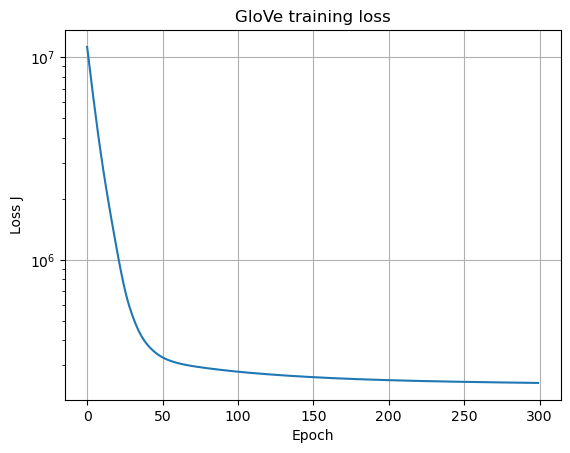

In [31]:
# @title c6.2 [0pt]
import matplotlib.pyplot as plt
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Loss J")
plt.title("GloVe training loss")
plt.yscale("log")  # log scale shows both the steep start and the slow tail
plt.grid()
plt.show()

<font color="orange">**How and why:**</font>

<font color="orange">I plot the stored loss for each epoch, on a log y-axis so both the steep start and the long tail are visible.</font>
<font color="orange">The shape is what you would expect from gradient descent on a smooth least-squares objective. The loss drops very fast in the first tens of epochs, while the random vectors move toward the large structure of $\log X$. It then flattens into a slowly decreasing tail, because the model only refines details and Adam's steps get smaller. The curve never goes up, because we optimise the exact full-batch loss (no mini-batch noise).</font>

<font color="red">**Don't clear the output of the above cell!**</font>

### Validation (Similarity)

Curious to see what this network has learned? Let's perform a simple validation experiment.

We will check which words the model considers the most similar to other words. To that end, we need a notion of __similarity__. One of the most common measures of similarity in high-dimensional vector spaces is the cosine similarity.

The cosine similarity of two vectors $\vec{a}, \vec{b}$ is given as:
$$sim(\vec{a}, \vec{b}) = \frac{\vec{a}\cdot \vec{b}}{|\vec{a}|_2 \cdot |\vec{b}|_2}$$

where $|\vec{x}|_2$ is the $L_2$-norm of the $\vec{x}$.

The function `similarity` below accepts two words, a vocabulary and the network's output vectors, and computes the similarity between these two words. For an outside-vocabulary word similarity is 0.

In [32]:
def similarity(word_i: str, word_j: str, vocab: Dict[str, int], vectors: FloatTensor) -> float:
    if not(word_i in vocab and word_i in vocab): return 0.
    i, j = vocab[word_i], vocab[word_j]
    v_i = vectors[i] / torch.linalg.vector_norm(vectors[i])  # a/|a|
    v_j = vectors[j] / torch.linalg.vector_norm(vectors[j])  # b/|b|
    sim = torch.dot(v_i, v_j)
    return sim

Let's check out some examples. Consider the word pairs below and, optionally, add your own word pairs if it helps to support your answer:

In [33]:
word_vectors = network.get_vectors().detach()

for pair in [
    ("cruciatus", "imperius"),
    ("avada", "kedavra"),
    ("hogwarts", "school"),
    ("goblin", "hagrid"),
    ("giant", "hagrid"),
]:
    print(f"Similarity between '{pair[0]}' and '{pair[1]}' is: {similarity(pair[0], pair[1], vocab, word_vectors)}")

Similarity between 'cruciatus' and 'imperius' is: 0.49876099824905396
Similarity between 'avada' and 'kedavra' is: 0.6552069783210754
Similarity between 'hogwarts' and 'school' is: 0.7654939293861389
Similarity between 'goblin' and 'hagrid' is: 0.27460336685180664
Similarity between 'giant' and 'hagrid' is: 0.5027310848236084


#### i3 [1pt]
Give an interpretation of the results. Do the scores correspond well to your perceived similarity of these word pairs?

**ANSWER**: <font color="red">Yes, the scores mostly agree with how similar these pairs feel. `hogwarts-school` (0.77) and `avada-kedavra` (0.66) are the highest. *Avada Kedavra* is a fixed phrase and Hogwarts is literally "Hogwarts School of Witchcraft and Wizardry", so both pairs appear in the same contexts. `cruciatus-imperius` (0.50) is moderately similar. Both are Unforgivable Curses that appear in the same scenes, with the same neighbours (*curse*, *moody*, *neville*/*harry*).</font>

<font color="red">The pair `giant-hagrid` (0.50) scores almost twice as high as `goblin-hagrid` (0.27), which is correct: Hagrid is half-giant, and his storyline (Grawp, Madame Maxime, the giants in book 5) shares many contexts with `giant`. Goblins mostly appear with *griphook* and *sword* (the Gringotts plot of book 7), where Hagrid hardly appears. GloVe similarity reflects shared contexts, so these values are what we would expect.</font>

To obtain the similarities of one word against all other words in the corpus, use torch functions and follow the equation ($\vec{c}_i$ is $i$th row of $\mathbf{C}$):
$$sim(\vec{w}, \mathbf{C}) = \frac{\vec{w}\cdot \mathbf{C}}{|\vec{w}|_2 \cdot |\mathbf{C}|_2} = \Big(\frac{\vec{w}\cdot \vec{c}_1}{|\vec{w}|_2 \cdot |\vec{c}_1|_2},\ldots,\frac{\vec{w}\cdot \vec{c}_N}{|\vec{w}|_2 \cdot |\vec{c}_N|_2}\Big)$$

Using `similarity` as a reference, write `similarities`, which accepts one word, a vocabulary and the network's output vectors and computes the similarity between the word and the entire corpus. **If a word is out of vocabulary, it should return a matrix of 0 similarities.**

_Hint_: $\mathbf{C} \in \mathbb{R}^{N, D}$, $\vec{w} \in \mathbb{R}^{1, D}$, $sim(\vec{w}, \mathbf{C}) \in \mathbb{R}^{1, N}$

In [34]:
# @title c7 [4pt]
def similarities(word_i: str, vocab: Dict[str, int], vectors: FloatTensor) -> FloatTensor:
    # use torch functions. Don't iterate over rows of vectors matrix!
    if word_i not in vocab:
        return torch.zeros(1, len(vocab))                           # 1 x N zeros for OOV words
    w = vectors[vocab[word_i]]                                      # (D,)
    w_unit = w / torch.linalg.vector_norm(w)                        # w / |w|
    C_unit = vectors / torch.linalg.vector_norm(vectors, dim=1, keepdim=True)  # every row c_n / |c_n|
    return (C_unit @ w_unit).reshape(1, -1)                         # (N,) -> 1 x N

<font color="orange">**How and why:**</font>

<font color="orange">Cosine similarity is the dot product of unit-length vectors. So I normalise the query vector **and every row of the matrix separately**. `vector_norm(vectors, dim=1, keepdim=True)` gives an $N \times 1$ column of row norms, which broadcasts in the division.</font>
<font color="orange">One matrix-vector product `C_unit @ w_unit` then gives all $N$ similarities at once, and I reshape them to $1 \times N$.</font>

<font color="orange">Bug fix: the earlier version divided by `vector_norm(vectors)` without `dim`, which is the norm of the *whole matrix*. That is the same number for every row, so the result was the raw dot product scaled by a constant, not a cosine similarity. Words with long vectors were then ranked too high, regardless of direction. Out-of-vocabulary words return a $1 \times N$ tensor of zeros, as specified.</font>

In [35]:
# TEST c7a
assert similarities('harry', vocab, word_vectors).shape == torch.Size([1, len(vocab)])
assert similarities('cow', vocab, word_vectors).shape == torch.Size([1, len(vocab)])

Now we can manipulate the word vectors to find out what the corpus-wide most similar words to a query word are!

In [36]:
def most_similar(word_i: str, vocab: Dict[str, int], vectors: FloatTensor, k: int) -> List[str]:
    """ Returns a list of k words that are most similar to word_i
        The list excludes word_i itself
    """
    sims = similarities(word_i, vocab, vectors)
    _, topi = sims.topk(dim=-1, k=k+1)
    topi = topi.view(-1).cpu().numpy().tolist()
    inv = {v: i for i, v in vocab.items()}
    return [inv[i] for i in topi if inv[i] != word_i][:k]

In [37]:
# TEST c7b
for word in [
    "forbidden", "myrtle", "gryffindor", "wand", "quidditch", "marauder",
    "horcrux", "phoenix", "triwizard", "screaming", "letter"
]:
    print(f"Most similar words to '{word}': {most_similar(word, vocab, word_vectors, 6)}")

Most similar words to 'forbidden': ['shadows', 'grounds', 'forest', 'lawns', 'mountains', 'ahead']
Most similar words to 'myrtle': ['moaning', 'bathroom', 'hid', 'toilet', 'sobbing', 'properly']
Most similar words to 'gryffindor': ['ravenclaw', 'team', 'wood', 'possession', 'quidditch', 'beat']
Most similar words to 'wand': ['spoke', 'face', 'shot', 'onto', 'struggled', 'flew']
Most similar words to 'quidditch': ['winning', 'saturday', 'team', 'training', 'captain', 'seeker']
Most similar words to 'marauder': ['lucky', 'gotten', 'convinced', 'map', 'locked', 'set']
Most similar words to 'horcrux': ['sword', 'object', 'goblin', 'destroy', 'horcruxes', 'safe']
Most similar words to 'phoenix': ['feather', 'fawkes', 'spinning', 'building', 'connected', 'murder']
Most similar words to 'triwizard': ['tournament', 'champions', 'cedric', 'cup', 'champion', 'quidditch']
Most similar words to 'screaming': ['frozen', 'scream', 'voices', 'screams', 'cold', 'forced']
Most similar words to 'letter':

#### i4 [3pt]

Interpret the results in the context of Harry Potter books.
- Do these most similar words make sense (are they actually similar to the query words)?
- Are there any patterns you can see in the "errors" (the words that you wouldn't consider actually similar to the query word in general, in everyday life)?
- Which examples are instances of similarity (if any) and relatedness (if any)?
- Any other observations are welcome.

Illustrate your answers with examples from your model's output.

**ANSWER**: <font color="red">**Do they make sense?** Mostly yes, within the world of the books. `triwizard → tournament, champions, cedric, cup, champion`, `myrtle → moaning, bathroom, toilet, sobbing` and `letter → letters, hedwig, errol, ink, written` are good neighbour lists. `quidditch → team, training, captain, seeker, saturday` and `horcrux → sword, destroy, horcruxes, goblin` describe the topic well.</font>

<font color="red">**Patterns in the errors.** (1) *Very frequent words* get diffuse vectors. `wand` (1652 occurrences) appears in almost every action scene, so its neighbours are generic narrative words: *spoke, face, shot, onto, struggled, flew*. (2) *Rare words* get noisy vectors. `marauder` (43 times) only gets *map* right, next to noise such as *lucky* and *gotten*. `phoenix` gets *fawkes* and *feather* but also *building*, *connected* and *murder*. (3) *Plot-specific associations*: `horcrux → sword, goblin` (Gryffindor's sword, Griphook) and `screaming → frozen, cold` (the Dementor scenes) are true in the books but not in everyday language.</font>

<font color="red">**Similarity vs relatedness.** Real *similarity* (words of the same type that could replace each other): `gryffindor → ravenclaw`, `triwizard → quidditch` (both competitions), and morphological variants such as `horcrux → horcruxes`, `letter → letters` and `screaming → scream/screams`. `phoenix → fawkes` is an instance of the category. Most neighbours show *relatedness* (words that appear together): `forbidden → forest, grounds, lawns`, `myrtle → bathroom, toilet`, `gryffindor → team, possession, wood` (Quidditch commentary: "Gryffindor in possession", Oliver Wood), and `letter → hedwig, errol` (the owls that deliver letters). GloVe captures relatedness more strongly than similarity, because it is trained on co-occurrence in a wide window.</font>

Overall it's quite impressive; we managed to encode a meaningful portion of the corpus statistics in only $30$ numbers per word!
(A compression ratio of >99%)

<div class="alert alert-block alert-info">
<b>Note:</b> The word vectors obtained by this process are (to a small extent) random, due to the random initialization of the embedding layers. If you are unhappy with your results, you can repeat the experiment a few times or try to toy around with the hyper-parameters (the smoothing factor of ${X}$, $x_{max}$, $\alpha$, the number of epochs and the dimensionality of the vector space). But do this as your own experiments outside the submission file.
</div>

Word vectors, however, contain way more information than just word co-occurrence statistics. Hold tight until the next assignment, where we will see how word vectors may be used to infer information spanning entire phrases and sentences.

### Validation (Word Analogies)

From the paper:
> The word analogy task consists of questions like "$a$ is to $b$ as $c$ is to __?" To correctly answer this question, we must find the word $d$ such that $w_d \approx w_b - w_a + w_c$ according to the cosine similarity.

Write your own function that performs the word analogy task.  

In addition to the standard approximation $w_d \approx w_b - w_a + w_c$, implement another non-standard but intuitive approximation where we are searching $w_d$ that maximizes the following similarity $w_a - w_b \approx w_c - w_d$.  

Let's see which criteria will give the best results, or maybe both give the same results.    

_Hint_: Take a look at the code a few cells back. Most of what you need is already there.

In [38]:
# @title c8 [5pt]
def analogy(
    word_a: str, word_b: str, word_c: str, vocab: Dict[str, int],
    vectors: FloatTensor, k: int=5, standard: bool=True
) -> List[str]:
    """ Return a list of k words whose vectors are most similar to the solution vector of the analogy.
        The first element means the most similar, followed by the rest in decreasing similarity.
        word_a, word_b, and word_c are never returned as a part of the list.
        param standard=True uses the standard approximation equation, =False uses the alternative one.
    """
    a, b, c = vectors[vocab[word_a]], vectors[vocab[word_b]], vectors[vocab[word_c]]
    unit = lambda M: M / torch.linalg.vector_norm(M, dim=-1, keepdim=True)  # row-wise L2 normalisation

    if standard:
        # w_d ~ w_b - w_a + w_c : cosine between the target vector and every word vector
        sims = unit(vectors) @ unit(b - a + c)
    else:
        # w_a - w_b ~ w_c - w_d : cosine between (a - b) and (c - d) for every candidate d at once
        sims = unit(c - vectors) @ unit(a - b)   # c - vectors broadcasts to an N x D matrix
        sims[vocab[word_c]] = -float("inf")      # c - c is the zero vector -> undefined (nan) cosine

    inv = {i: w for w, i in vocab.items()}
    excluded = {word_a, word_b, word_c}
    # take k + 3 candidates so that we still have k left after removing a, b and c
    top = sims.topk(k + len(excluded)).indices.tolist()
    return [inv[i] for i in top if inv[i] not in excluded][:k]

<font color="orange">**How and why:**</font>

- <font color="orange">**Standard:** build the target vector $w_b - w_a + w_c$ and rank all words by cosine similarity to it, using the same row-wise normalisation as in `similarities`.</font>
- <font color="orange">**Alternative:** we want the $d$ for which $w_c - w_d$ points in the same direction as $w_a - w_b$. Broadcasting `c - vectors` builds the $N \times D$ matrix of all candidate differences $w_c - w_d$ at once. Normalising its rows and multiplying by the normalised $w_a - w_b$ gives the cosine for every candidate in one step. For $d = c$ the difference is the zero vector, so its cosine is undefined (NaN). I set it to $-\infty$ so it can never be picked.</font>
- <font color="orange">`topk(k+3)`: we fetch three extra candidates, because up to three of the top results can be the input words $a, b, c$, which must be excluded. We still return exactly $k$ words.</font>

<font color="orange">Bug fix: the earlier version normalised by the norm of the whole matrix (the same problem as in `similarities`) and fetched only $k+1$ candidates.</font>

Some example triplets to test your analogies on:

In [39]:
# TEST c8
triplets = [("padma", "parvati", "fred"),
            ("avada", "kedavra", "expecto"),
            ("dungeon", "slytherin", "tower"),
            ("scabbers", "ron", "hedwig"),
            ("ron", "molly", "draco"),
            ("durmstrang", "viktor", "beauxbatons"),
            ("snape", "potions", "trelawney"),
            ("harry", "seeker", "ron")
            # ---------------------
            # YOUR CODE HERE (3 examples)
            , ("harry", "potter", "ron")             # expected: weasley
            , ("hermione", "granger", "draco")       # expected: malfoy
            , ("dumbledore", "hogwarts", "karkaroff") # expected: durmstrang
           ]

print("Mode: d ~ c - a + b")
for a, b, c in triplets:
    print("{:^16} is to {:^16} as {:^16} is to\t{}".format(a, b, c, analogy(a, b, c, vocab, word_vectors, 5, standard=True)))

print("\nMode: a - b ~ c - d")
for a, b, c in triplets:
    print("{:^16} is to {:^16} as {:^16} is to\t{}".format(a, b, c, analogy(a, b, c, vocab, word_vectors, 5, standard=False)))

Mode: d ~ c - a + b
     padma       is to     parvati      as       fred       is to	['pretending', 'george', 'mrs', 'told', 'ron']
     avada       is to     kedavra      as     expecto      is to	['patronum', 'slowed', 'dementor', 'hood', 'steam']
    dungeon      is to    slytherin     as      tower       is to	['gryffindor', 'training', 'points', 'hundred', 'ravenclaw']
    scabbers     is to       ron        as      hedwig      is to	['carrying', 'awake', 'parcel', 'time', 'five']
      ron        is to      molly       as      draco       is to	['coolly', 'narcissa', 'unaware', 'forgive', 'pleasantly']
   durmstrang    is to      viktor      as   beauxbatons    is to	['delacour', 'maxime', 'cedric', 'judges', 'support']
     snape       is to     potions      as    trelawney     is to	['herbology', 'divination', 'exams', 'exam', 'binns']
     harry       is to      seeker      as       ron        is to	['score', 'chasers', 'hufflepuff', 'flint', 'spectacular']
     harry       i

<font color="orange">**How and why:**</font>

<font color="orange">I added three analogies with a single clear answer: first name to surname (`harry : potter = ron : ?` gives *weasley*, and `hermione : granger = draco : ?` gives *malfoy*) and headmaster to school (`dumbledore : hogwarts = karkaroff : ?` gives *durmstrang*). Both modes are printed for every triplet, so they can be compared directly.</font>

Some minimal emergent intelligence :) *(hopefully..)*. 🧙‍♀️

#### i5 [2pt]

Which analogy equation did give the best results for the provided analogy samples?  

Come up with three additional analogies in the context of Harry Potter.
Add them to the list of analogies in the code above and run the analogy computation.

Interpret the results of the best performing analogy equation (if any):
- For which analogies did the model manage to guess the correct answers (taking the first word in the output to be the model's "guess")?
- For which analogies are the correct answers present in the top K words?
- Do you see any patterns in the cases when the model didn't solve the task correctly? In other words, when the model's guess was wrong, can you suggest why the model guessed what it guessed?

**ANSWER**: <font color="red">The **standard** equation ($d \approx c - a + b$) works clearly better. The alternative ($a - b \approx c - d$) solves only `durmstrang:viktor :: beauxbatons:delacour` and produces many unrelated words (*accidents, whenever, lunch, ere*). The reason is that for most candidates $\|w_d\|$ is large compared with $\|w_c\|$, so $w_c - w_d \approx -w_d$. The cosine then mostly ranks $d$ against the direction $b - a$ and loses almost all information about $c$.</font>

<font color="red">My three additions: `harry:potter :: ron:?`, `hermione:granger :: draco:?` and `dumbledore:hogwarts :: karkaroff:?`.</font>

<font color="red">*Correct first guess (standard):* `avada:kedavra :: expecto:`**patronum**, `dungeon:slytherin :: tower:`**gryffindor**, and `durmstrang:viktor :: beauxbatons:`**delacour** (Fleur Delacour).
*Correct answer in the top 5:* *george* (#2, for fred), *narcissa* (#2, Draco's mother), *divination* (#2, for trelawney), *durmstrang* (#2, for karkaroff), and *lucius* (#5, a Malfoy, for draco).
*Failures:* `scabbers:ron :: hedwig:?` returns *carrying, awake, parcel* instead of *harry*. `harry:seeker :: ron:?` returns *score, chasers* instead of *keeper*. `harry:potter :: ron:?` returns *actually, smiling, sneered, coolly* instead of *weasley*.</font>

<font color="red">*Patterns.* When the model is wrong, it usually lands in the right **topic** but not on the right **relation**. Hedwig gives what owls do (*carrying, parcel*). Ron as seeker gives other Quidditch words (*chasers, score*). The surname analogies fail because *"Potter"* and *"Weasley"* are mostly used as forms of address in hostile dialogue (*"Potter," sneered Malfoy*), so the offset `potter − harry` encodes "sneering speech" instead of "surname" (*sneered, coolly*). Also, the first guess is often a strongly co-occurring word of $c$ (*george* is next to *fred* almost always), because $w_c$ dominates the sum.</font>

# <font color="red">Challenge-based Assignment</font>

## Counting co-occurrences

In the beginning of the notebook you were provided with a pickle of co-occurrence counts. But how were these counts obtained?  
You will find this out when you complete this exercise.  

First, we obtain the plain text corpus of the Harry Potter book series and place the book files in the current directory.

In [40]:
!git clone https://github.com/ErikaJacobs/Harry-Potter-Text-Mining.git

fatal: destination path 'Harry-Potter-Text-Mining' already exists and is not an empty directory.


In [41]:
!cp Harry-Potter-Text-Mining/Book\ Text/* .

In research, it is relatively common that papers don't include all necessary details for replicating the experiments. This is often due to the lack of space in the paper, overlooking certain details, or simply a bad practice.

We will give you several hints on how the co-occurrence matrix was obtained. With the hints and the provided data in the pickle file, you should be able to replicate the exact content of the co-occurrence matrix from the pickle. Here are the hints:

1.   Tokenization of the data was done in a shallow but effective way: replace all punctuations with white space and delimit tokens on white space;
2.   `nltk` and `string` libraries where used for identifying punctuations and stopwords;
3.   Context windows are symmetric and don't span across chapters (i.e., the last word of chapter $N$ is not co-occuring with the first word of chapter $N+1$).
4.   The vocabulary was obtained based on the frequency cutoff.

How the context words were counted is something you need to find out.  
Remember that the provided pickle file includes a lot of information, so please utilize it wisely.

To replicate the co-occurrence counts, complete the function below. Then use it to find out the exact values of `cutoff` and `window_size` that result in the co-occurrence counts identical to the provided ones. No need to provide the code for finding the exact values. Just use them in the next TEST code cell.

Feel free to import any standard python library. Use the same cell code for importing libraries and defining auxiliary functions (if any).
The code will be evaluated not only on the correctness of the output but also on efficiency. It should be able to extract the counts and create the tensor in less than a minute (in the colab environment).

In [42]:
# @title c9 [8pt]
import csv, string, nltk, sys
import numpy as np
from collections import Counter
nltk.download('stopwords')

def read_book_files(files: List[str], cutoff: int=10, window_size: int=20,
                    verbose: bool=False):
    """ Input:
            file - a list of file paths;
            cutoff - vocab excludes words with occurrence counts < cutoff;
            window_size - size of the left and right windows (individually);
            verbose - when set to False prints nothing
        Outputs a tuple of:
            voc - mapping of vocabulary to indices;
            dd_cnt - dict of dict of co-occurrence counts based on the voc; (not a defaultdict)
            X - Tensor with |vocab|x|vocab| size and co-occurrence counts. This should be based on dd_cnt
    """
    csv.field_size_limit(sys.maxsize)                       # a chapter is one (very long) csv field
    stop = set(nltk.corpus.stopwords.words('english'))
    # every ASCII punctuation character -> a space (unicode punctuation such as '—' is kept)
    punct_to_space = str.maketrans(string.punctuation, ' ' * len(string.punctuation))

    # 1) one token list per chapter: the files are '@'-separated csv files with a row per chapter
    chapters = []
    for path in files:
        with open(path, newline='', encoding='utf-8') as f:
            reader = csv.reader(f, delimiter='@')
            next(reader)                                    # skip header "Text"@"Chapter"@"Book"
            chapters += [row[0].lower().translate(punct_to_space).split() for row in reader]

    # 2) vocabulary: non-stopwords with frequency >= cutoff, indexed in alphabetical order
    freq = Counter(tok for chapter in chapters for tok in chapter)
    voc = {w: i for i, w in enumerate(sorted(w for w, c in freq.items() if c >= cutoff and w not in stop))}
    N = len(voc)

    # 3) count co-occurrences. Windows run over the FULL token stream of a chapter
    #    (stopwords / rare words take up window positions) but only vocab-vocab pairs are counted.
    #    For each distance d = 1..window_size, every pair (t, t+d) is a co-occurrence in both directions.
    pair_keys = []
    for chapter in chapters:
        ids = np.fromiter((voc.get(t, -1) for t in chapter), dtype=np.int64, count=len(chapter))
        for d in range(1, window_size + 1):
            left, right = ids[:-d], ids[d:]
            keep = (left >= 0) & (right >= 0)               # both tokens must be in the vocab
            pair_keys.append(left[keep] * N + right[keep])  # (left word, right word)
            pair_keys.append(right[keep] * N + left[keep])  # (right word, left word): symmetric window
    counts = np.bincount(np.concatenate(pair_keys), minlength=N * N).reshape(N, N)

    # 4) dd_cnt: word -> {context word: count}, only non-zero counts (a plain dict, not a defaultdict)
    words = sorted(voc, key=voc.get)                        # index -> word
    rows, cols = np.nonzero(counts)
    dd_cnt = {}
    for i, j, c in zip(rows.tolist(), cols.tolist(), counts[rows, cols].tolist()):
        dd_cnt.setdefault(words[i], {})[words[j]] = c

    # 5) X is filled from dd_cnt
    idx_i = [voc[w] for w, ctx in dd_cnt.items() for _ in ctx]
    idx_j = [voc[c] for ctx in dd_cnt.values() for c in ctx]
    vals = [v for ctx in dd_cnt.values() for v in ctx.values()]
    X = torch.zeros(N, N, dtype=torch.long)
    X[idx_i, idx_j] = torch.tensor(vals, dtype=torch.long)

    if verbose:
        print(f"{len(chapters)} chapters, {sum(map(len, chapters))} tokens, |V| = {N}, total count = {X.sum().item()}")
    return voc, dd_cnt, X

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/stijnroos/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


<font color="orange">**How and why:**</font>

<font color="orange">The function follows the hints, plus what I could infer from the pickle:</font>
1. <font color="orange">**Reading:** each book file is a csv file with `@` as delimiter and one row per chapter (columns `Text`, `Chapter`, `Book`). So each row's text is one chapter, which makes it easy to keep windows inside chapters (hint 3).</font>
2. <font color="orange">**Tokenisation (hints 1 and 2):** lowercase, map every character in `string.punctuation` to a space with `str.translate`, then split on whitespace. Only ASCII punctuation is removed, which is why tokens such as `'—'`, `'”'` and `'¨c'` appear in the provided vocabulary.</font>
3. <font color="orange">**Vocabulary (hint 4):** count all tokens, then keep words that are **not** NLTK stopwords and occur at least `cutoff` times. The provided vocab is in alphabetical order (`'1'` gets id 0), so I sort it.</font>
4. <font color="orange">**Counting (the part we had to discover):** the window is taken over the **full** token stream, so stopwords and rare words take up window positions, but a pair is only counted if **both** tokens are vocabulary words. The diagonal is not zero (`X[harry, harry]` = 11504), so a word that occurs twice within one window does count as its own context.</font>
5. <font color="orange">**Efficiency:** instead of a Python double loop (about 1.1M tokens × 50 neighbours), I map tokens to ids (-1 for words outside the vocabulary) and loop only over the distance $d = 1..w$. For each $d$, slicing `ids[:-d]` and `ids[d:]` gives all pairs at that distance as NumPy arrays. One `np.bincount` over the encoded pair index $iN + j$ then counts everything at once. Each pair is added in both directions, which gives the symmetric matrix.</font>
6. <font color="orange">`dd_cnt` (a plain dict of dicts with only non-zero counts) is built from the count matrix, and `X` is then filled from `dd_cnt` with one vectorised index assignment, as the docstring requires.</font>

<font color="orange">The whole function runs in a few seconds, well below the 60-second limit.</font>

In [43]:
en_stop = set(nltk.corpus.stopwords.words('english'))
en_stop

{'a',
 'about',
 'above',
 'after',
 'again',
 'against',
 'ain',
 'all',
 'am',
 'an',
 'and',
 'any',
 'are',
 'aren',
 "aren't",
 'as',
 'at',
 'be',
 'because',
 'been',
 'before',
 'being',
 'below',
 'between',
 'both',
 'but',
 'by',
 'can',
 'couldn',
 "couldn't",
 'd',
 'did',
 'didn',
 "didn't",
 'do',
 'does',
 'doesn',
 "doesn't",
 'doing',
 'don',
 "don't",
 'down',
 'during',
 'each',
 'few',
 'for',
 'from',
 'further',
 'had',
 'hadn',
 "hadn't",
 'has',
 'hasn',
 "hasn't",
 'have',
 'haven',
 "haven't",
 'having',
 'he',
 "he'd",
 "he'll",
 "he's",
 'her',
 'here',
 'hers',
 'herself',
 'him',
 'himself',
 'his',
 'how',
 'i',
 "i'd",
 "i'll",
 "i'm",
 "i've",
 'if',
 'in',
 'into',
 'is',
 'isn',
 "isn't",
 'it',
 "it'd",
 "it'll",
 "it's",
 'its',
 'itself',
 'just',
 'll',
 'm',
 'ma',
 'me',
 'mightn',
 "mightn't",
 'more',
 'most',
 'mustn',
 "mustn't",
 'my',
 'myself',
 'needn',
 "needn't",
 'no',
 'nor',
 'not',
 'now',
 'o',
 'of',
 'off',
 'on',
 'once',
 'on

In [44]:
%%time
# TEST
# Fill in the found cutoff and window_size values
# Cell execution shouldn't take more than 60sec
my_vocab, my_contexts, my_X = \
    read_book_files([ f"HPBook{n}.txt" for n in range(1,8) ],
                    cutoff=16, window_size=25)

CPU times: user 2.8 s, sys: 462 ms, total: 3.27 s
Wall time: 2.6 s


<font color="orange">**How and why:**</font>

<font color="orange">I filled in the values I found: `cutoff=16` and `window_size=25`. As before, `%%time` is moved to the first line so the cell magic works in current IPython.</font>

In [45]:
# Verification: the reconstruction is identical to the provided pickle
print("same vocab:   ", my_vocab == vocab)
print("same contexts:", my_contexts == contexts)
print("same X:       ", torch.equal(my_X, X))

same vocab:    True


same contexts: True
same X:        True


<font color="orange">**How and why:**</font>

<font color="orange">This cell checks the reconstruction against the provided pickle. The vocabulary (words *and* ids), the dict of context counts, and the full $4298 \times 4298$ tensor are all **identical**, so the parameters and the counting procedure reproduce the original exactly.</font>

In [46]:
# TEST c9
# This makes sure the value types are as expected
assert my_vocab['1'] == 0
assert isinstance(my_vocab, dict)
assert isinstance(my_contexts, dict)
assert 'potter' in my_contexts['harry']
assert isinstance(my_X, torch.Tensor)

<font color="red">**Don't clear the output of the above cell!**</font>

#### i6 [1pt]

What are the values of `cutoff` and `window_size` that replicates the provided counts?

**Describe** <font color="red">with 50-100 words</font> the process of finding the correct underlying algorithm of `read_book_files` and how the correct values of `cutoff` and `window_size` were found.

Assume that we have access only to the contents of the pickle file and the Harry Potter text corpus.
Devise an optimal strategy for determining the values of `cutoff` and `window_size` that only counts tokens in the corpus.
**Describe** the strategy and illustrate it with actual tokens and their counts from the pickle file and the corpus.

**ANSWER**: <font color="red">`cutoff = 16`, `window_size = 25`.</font>

<font color="red">**Finding the algorithm.** The pickle itself gives the clues. The vocabulary is in alphabetical order (`'1'` = 0), contains no NLTK stopwords, and does contain unicode marks (`'—'`, `'”'`, `'¨c'`). So only `string.punctuation` was replaced by spaces, the text was lowercased, and stopwords were dropped from the vocabulary. `X` is symmetric with a non-zero diagonal (`X[harry,harry]` = 11504), so windows are symmetric and repeated words count as their own context. One open question remained: are the stopwords and rare words removed *before* the window is applied? I tested three streams: (a) the full token stream, (b) the stream without stopwords, and (c) the stream with only vocabulary words. Only (a) fits: windows run over the full text, but only vocabulary-vocabulary pairs are counted.</font>

<font color="red">**Strategy that only counts tokens.** (1) *Cutoff:* count every token's frequency in the corpus. The cutoff is the frequency of the rarest vocabulary word, and it must be higher than that of every excluded non-stopword. The rarest vocabulary words (`abbott`, `advancing`, `aimed`, `aisle`, `alecto`) occur exactly 16 times. The most frequent excluded non-stopwords occur 15 times, so the cutoff is 16. (2) *Window:* take a rare vocabulary word and use its row sum. `abbott` (16 occurrences) has row sum 387 in the pickle, so its 16 occurrences have on average 24 vocabulary words around them. For each occurrence, count the vocabulary tokens within ±w positions and increase w until the total reaches 387. This total grows with w, so a binary search works. With the full stream, w = 24 gives too little and w = 25 gives exactly 387, and the whole row is equal (`hannah` 15, `harry` 11, `said` 9, ...). The same w explains `advancing` (365) and `harry` (419907). Finally, I checked that w = 25 reproduces the total of `X`, 11,674,820, exactly (w = 24 gives 11,207,512 and w = 26 gives 12,143,372), and that the whole matrix is equal.</font>

# <font color="red">Work description</font>

~~Describe your approach to solving the exercises, for example, what steps you took first, followed by subsequent actions, which parts you found most challenging or easy, any specific helpful assistance received from TAs, whether you used GenAI, to what extent, at what stage, which one, how helpful was it, etc.~~

<font color="red">YOUR ANSWER HERE</font>   [100-200 words]

# Acknowledgment

The jupyter notebook was initially created by Konstantinos Kogkalidis and Tejaswini Deoskar.  
Recent changes, including adaptation to the Colab environment and the exercise on reconstructing a co-occurrence matrix, are by Lasha Abzianidze.